# Air Temperature compression: scikit-learn LinearRegression → exported affine formula → residuals → ANS

A single CPU-only scikit-learn LinearRegression fit uses shuffled paired eight-observation training windows. Its copied immutable coefficients define an equivalent NumPy affine formula; parity is implementation equivalence, not model optimization. The chronological test partition remains reserved.


This study used the available scikit-learn 1.7.2 environment; scikit-learn is a notebook-specific dependency and is not declared in the project Poetry dependencies. All fitting and prediction run on CPU.


## 1. Load and check the observed series

We preserve file order rather than sorting timestamps: duplicates and the recorded backward step are properties of this observed sequence. The original decimal strings are retained so the source grid can be inferred from training text only. This section loads libraries and verifies the expected source file.


In [1]:
import os, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
try:
    from threadpoolctl import threadpool_limits
except ImportError:
    threadpool_limits = None
import matplotlib.pyplot as plt
_repo_candidates=[Path.cwd(),Path.cwd().parent,*[Path(entry) for entry in sys.path if entry]]
root=next((candidate.resolve() for candidate in _repo_candidates if (candidate/'compression_evaluation').is_dir()),None)
if root is None: raise RuntimeError('Could not locate repository compression_evaluation package')
sys.path.insert(0,str(root))
from compression_evaluation.poc import (chronological_bounds, impute_training_only, infer_decimal_quantum, make_windows, checked_ticks, snap_to_grid, fit_training_alphabet, evaluate_suffix, benchmark_pairs, make_codec_pair, pinned_allowed_cpu)
from compression_evaluation.poc_plots import plot_training_series, plot_training_distribution
np.random.seed(42)
print('scikit-learn:',__import__('sklearn').__version__,'CPU-only estimator; no GPU path')


scikit-learn: 1.7.2 CPU-only estimator; no GPU path


### Read the source and verify recorded chronology

Row counts, timestamp irregularities, and the missing value are checked explicitly. No temporal repair or reordering is performed.


In [2]:
csv=root/'datasets/AriviyalN_Data_Air_Temperature.csv'
a=pd.read_csv(csv,dtype={'Air Temperature':'string'})
a['Timestamp']=pd.to_datetime(a['Timestamp'],dayfirst=True,errors='coerce')
assert len(a)==51354 and a.Timestamp.notna().all()
backwards=int((a.Timestamp.diff()<pd.Timedelta(0)).sum()); duplicates=int(a.Timestamp.duplicated().sum())
assert (backwards,duplicates)==(1,192)
text=a['Air Temperature'].reset_index(drop=True)
values=pd.to_numeric(text,errors='coerce').to_numpy(dtype=np.float64)
n=len(values); train_end,val_end=chronological_bounds(n)
assert (train_end,val_end)==(35947,46218)
missing=np.flatnonzero(np.isnan(values)); assert missing.tolist()==[34567]
values=impute_training_only(values,train_end,val_end)
step=float(infer_decimal_quantum(text.iloc[:train_end])); assert step==.1
train,valid=values[:train_end],values[train_end:val_end]
print(f'Rows={n}; duplicates={duplicates}; backwards={backwards}; split={train_end}/{val_end}/{n}; step={step}; reserved test rows={n-val_end}')


Rows=51354; duplicates=192; backwards=1; split=35947/46218/51354; step=0.1; reserved test rows=5136


## 2. Split chronologically and inspect training data

The fixed positional 70/20/10 split separates earliest training, later validation, and final reserved test observations. Only training-side missing data may be imputed. One-step windows stay inside their partition, so no context crosses a boundary.


### Form within-partition windows and inspect plots

Training pairs are shuffled once with the fixed seed for fitting; this does not change chronological boundaries or the sequence plots. The validation contexts remain in their original order.


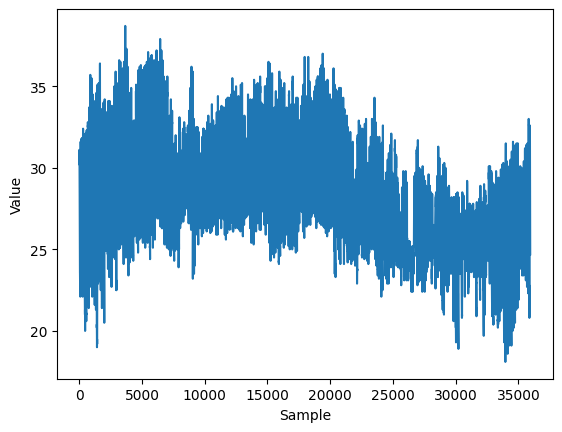

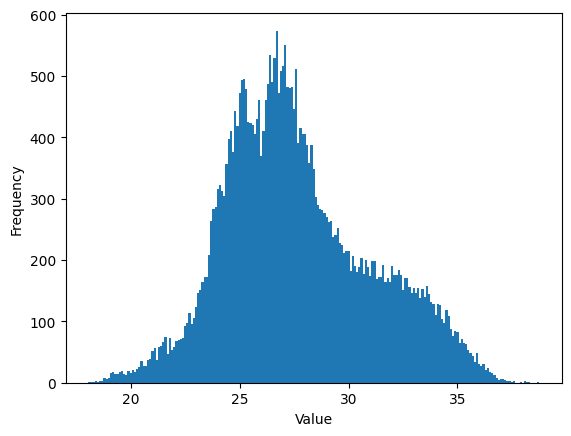

Training windows: (35939, 8) validation: (10263, 8) training pairs shuffled once with seed 42


In [3]:
X_train_ordered,y_train_ordered=make_windows(train); X_valid,y_valid=make_windows(valid)
order=np.random.default_rng(42).permutation(len(X_train_ordered)); X_train,y_train=X_train_ordered[order],y_train_ordered[order]
fig=plot_training_series(train); plt.show()
fig=plot_training_distribution(train,step); plt.show()
print('Training windows:',X_train.shape,'validation:',X_valid.shape,'training pairs shuffled once with seed 42')


### Verify split counts

The validation study starts with eight observed values as bootstrap context; only subsequent values are coded.


In [4]:
assert len(train)==35947 and len(valid)==10271 and n-val_end==5136
assert X_train.shape==(35939,8) and X_valid.shape==(10263,8)
print('Train rows/windows:',len(train),len(X_train),'validation rows/windows:',len(valid),len(X_valid),'reserved test rows:',n-val_end)


Train rows/windows: 35947 35939 validation rows/windows: 10271 10263 reserved test rows: 5136


## 3. Fit once on CPU and report raw prediction quality

One CPU fit uses paired training windows shuffled once with seed 42; validation never participates in fitting. Raw prediction MAE/MSE are compared with persistence. The gate requires both train-and-validation criteria to improve.


### Fit LinearRegression once on paired windows

The estimator receives the shuffled pair arrays once, with a flattened target. No subsequent cell refits it.


In [5]:
model=LinearRegression()
fit_start=time.perf_counter()
model.fit(X_train,y_train.ravel())
fit_seconds=time.perf_counter()-fit_start
assert model.coef_.shape==(8,) and np.ndim(model.intercept_)==0
print('Single CPU fit seconds:',fit_seconds,'estimator=LinearRegression()')


Single CPU fit seconds: 0.026440116998855956 estimator=LinearRegression()


### Define finite float64 sklearn prediction

The sklearn predictor validates finite float64 input and returns exactly finite `(n, 1)` output. The fitted CPU model is never moved to GPU.


In [6]:
def _validated_input(X):
    X=np.asarray(X,dtype=np.float64)
    if X.ndim!=2 or X.shape[1]!=8 or X.shape[0]<1 or not np.isfinite(X).all(): raise ValueError('input must be finite float64 with shape (n, 8)')
    return X

def numeric_predict(X):
    X=_validated_input(X)
    result=np.asarray(model.predict(X),dtype=np.float64).reshape(-1,1)
    if result.shape!=(len(X),1) or not np.isfinite(result).all(): raise ValueError('sklearn prediction must be finite (n,1)')
    return result


### Compute raw metrics and persistence comparison

These metrics are unsnapped model errors and must not be confused with decoded reconstruction error. A failing quality gate is reported, not hidden.


In [7]:
def report_metrics(pred,y):
    e=np.asarray(y).reshape(-1)-np.asarray(pred).reshape(-1)
    return {'MAE':float(np.mean(np.abs(e))),'MSE':float(np.mean(e**2))}
Xtr,ytr=make_windows(train)
train_pred=numeric_predict(Xtr); valid_pred=numeric_predict(X_valid)
train_base=Xtr[:,-1,None]; valid_base=X_valid[:,-1,None]
print('Train sklearn:',report_metrics(train_pred,ytr),'persistence:',report_metrics(train_base,ytr))
print('Validation sklearn:',report_metrics(valid_pred,y_valid),'persistence:',report_metrics(valid_base,y_valid))

numeric_valid_metrics = report_metrics(valid_pred, y_valid)
persistence_valid_metrics = report_metrics(valid_base, y_valid)
quality_gate_pass = all(numeric_valid_metrics[key] < persistence_valid_metrics[key] for key in ('MAE', 'MSE')) and all(report_metrics(train_pred,ytr)[key] < report_metrics(train_base,ytr)[key] for key in ('MAE', 'MSE'))
print('Sklearn train and validation quality gate:', 'PASS' if quality_gate_pass else 'FAIL', '(both MAE and MSE must improve on each split)')


Train sklearn: {'MAE': 0.16825664977763952, 'MSE': 0.07966221772625044} persistence: {'MAE': 0.21553465594479534, 'MSE': 0.11484821503102478}
Validation sklearn: {'MAE': 0.16719011087510888, 'MSE': 0.08245862105585014} persistence: {'MAE': 0.21583357692682456, 'MSE': 0.12135925168079509}
Sklearn train and validation quality gate: PASS (both MAE and MSE must improve on each split)


## 4. Inspect signed training residuals

Residual coding compares each target tick with the predictor output snapped to the training-inferred 0.1 grid. The signed residual is target minus snapped prediction: positive means above prediction, negative means below. This is a codec diagnostic, not the raw predictor error.


### Derive training-only signed ticks and view their distribution

No validation values influence the residual alphabet. The histogram reports signed physical residuals; the half-tick check illustrates why snapping and its rounding boundary matter.


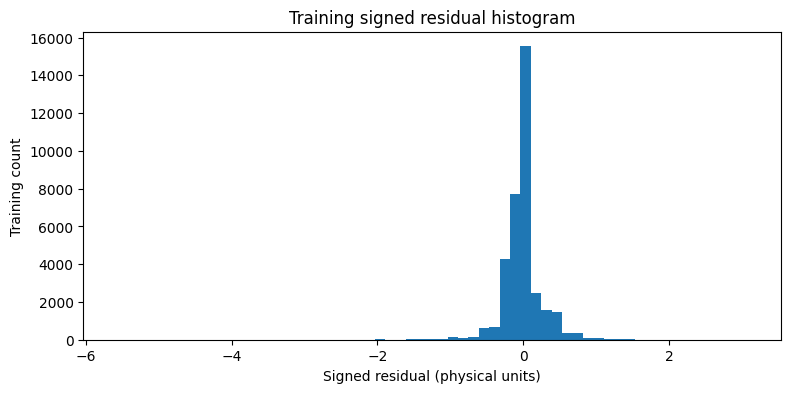

Signed residual ticks: 35939 min/max: -56 31 ; snap boundary check passed


In [8]:
train_target_ticks=checked_ticks(ytr,step,'training targets')
train_prediction_ticks=checked_ticks(snap_to_grid(train_pred,step),step,'snapped training predictions')
train_residual_ticks=train_target_ticks-train_prediction_ticks
train_signed_residuals=train_residual_ticks.astype(np.float64)*step
assert len(train_signed_residuals)==len(ytr) and np.isfinite(train_signed_residuals).all()
plt.figure(figsize=(9,4)); plt.hist(train_signed_residuals,bins=61); plt.xlabel('Signed residual (physical units)'); plt.ylabel('Training count'); plt.title('Training signed residual histogram'); plt.show()
half=step/2; left=np.array([[half-np.spacing(half)*4]]); right=np.array([[half+np.spacing(half)*4]])
assert np.allclose(left,right,rtol=1e-10,atol=1e-10) and int(np.rint(left[0,0]/step)) != int(np.rint(right[0,0]/step))
print('Signed residual ticks:',len(train_residual_ticks),'min/max:',int(train_residual_ticks.min()),int(train_residual_ticks.max()),'; snap boundary check passed')


## 5. Fit the training alphabet and check quantization / ANS

Only training targets and single-fit sklearn training predictions fit the padded signed residual support and normalized frequency table. Validation residuals may fall outside this support and must then fail explicitly rather than silently expand the alphabet. ANS symbols are zero-based indices derived from signed ticks.


### Build and inspect the fixed training-fitted frequency table

The model and table are shared read-only study state and are not transmitted in the measured payload. Frequencies are positive integers summing to 1024.


In [9]:
alphabet=fit_training_alphabet(ytr,train_pred,step,pad_ticks=5,total_frequency=1024)
print('Training alphabet ticks:',alphabet.low_tick,'..',alphabet.high_tick,'levels:',len(alphabet.frequencies),'frequency sum:',sum(alphabet.frequencies))
assert len(alphabet.frequencies)>0 and all(f>0 for f in alphabet.frequencies) and sum(alphabet.frequencies)==1024


Training alphabet ticks: -61 .. 36 levels: 98 frequency sum: 1024


### Quantizer support and symbol checks

The signed grid is preserved while the coder indexes the finite table. Off-grid and out-of-support symbols are rejected by the established quantizer/coder path.


In [10]:
from compression_evaluation.poc import SignedGridQuantizer
quantizer=SignedGridQuantizer(step,alphabet.low_tick,alphabet.high_tick)
assert quantizer.levels==len(alphabet.frequencies)
for symbol in range(quantizer.levels): assert quantizer.value_to_symbol(quantizer.symbol_to_value(symbol))==symbol
print('Quantizer boundary and supported-symbol roundtrip checks passed')


Quantizer boundary and supported-symbol roundtrip checks passed


## 6. Assemble independent codec pairs and bootstrap

Each encoder/decoder pair begins with its own copy of the same eight observed validation values. Those eight values are bootstrap state, not coded symbols. The table and model are shared study state; the measured payload excludes these metadata costs.


### Verify the bootstrap and independent histories

Factories create fresh pairs so previous encodes cannot affect later runs. Encoder and decoder prediction histories are separate and initialized identically.


In [11]:
validation_bootstrap=np.asarray(valid[:8],dtype=np.float64).copy()
validation_suffix=np.asarray(valid[8:],dtype=np.float64)
assert validation_bootstrap.shape==(8,) and len(validation_suffix)==10263

def validation_pair_factory(predictor):
    return make_codec_pair(validation_bootstrap,predictor,alphabet,step)


## 7. Evaluate numeric full-validation codec once

This single numeric study uses all 10,271 validation values: eight initialize rolling history and 10,263 suffix values are coded. Evaluator reconstruction metrics describe fidelity after coding, distinct from raw MAE/MSE. Entropy is a source statistic; actual finite-stream payload rate includes coder overhead.


### Run the sklearn full-validation study

This evaluator call is the one primary sklearn numeric pass. It is not the controlled paired CPU timing benchmark reported later.


In [12]:
ks=evaluate_suffix(valid,numeric_predict,alphabet,step)
print('Numeric full validation:',ks.metrics,'payload bytes:',ks.metrics.get('compressed_size_bytes'),'ratio:',ks.metrics.get('compression_ratio'),'entropy bits/symbol:',ks.entropy_bits,'bits/symbol:',ks.metrics.get('bits_per_symbol'),'bootstrap bytes/ratio:',ks.bootstrap_bytes,ks.bootstrap_ratio)
assert len(ks.symbols)==10263 and ks.bootstrap_bytes==ks.metrics['compressed_size_bytes']+64


Numeric full validation: {'encode_time_sec': 2.1999649299978046, 'encode_mem_mb': 231.890625, 'decode_time_sec': 1.7001571970031364, 'decode_mem_mb': 231.99609375, 'compression_ratio': 19.698656429942417, 'bits_per_symbol': 3.2489525479879178, 'mse': 5.9105766508696215e-30, 'snr_db': 321.3023882834084, 'uncompressed_size_bytes': 82104, 'compressed_size_bytes': 4168, 'symbol_count': 10263} payload bytes: 4168 ratio: 19.698656429942417 entropy bits/symbol: 3.1408941579779563 bits/symbol: 3.2489525479879178 bootstrap bytes/ratio: 4232 19.415879017013232


## 8. Export the fitted affine formula and verify parity

The formula uses copied coefficient and intercept values from the one fitted sklearn estimator. This is not an optimization and does not trigger another fit.


### Copy coefficients and implement affine arithmetic

Copied coefficients are read-only and have the contract shape `(8,)`; the intercept is scalar.


In [13]:
coef_export=np.asarray(model.coef_,dtype=np.float64).copy(); intercept_export=float(model.intercept_)
assert coef_export.shape==(8,) and np.isfinite(coef_export).all() and np.isfinite(intercept_export)
coef_export.setflags(write=False)
_export_snapshot=coef_export.copy(); _export_snapshot.setflags(write=False)
def affine_predict(X):
    X=_validated_input(X); result=(X@coef_export+intercept_export).reshape(-1,1)
    if result.shape!=(len(X),1) or not np.isfinite(result).all(): raise ValueError('affine result invalid')
    return result


### Check formula parity on training and full validation contexts

Raw outputs are compared with strict tolerance and snapped ticks must match exactly. This checks every validation context before the second codec study.


In [14]:
all_X=np.concatenate([Xtr,X_valid]); assert all_X.shape==(46202,8)
ta=numeric_predict(all_X); na=affine_predict(all_X)
raw_diff=float(np.max(np.abs(ta-na)))
assert np.allclose(ta,na,rtol=1e-10,atol=1e-10),f'raw parity failed: max abs diff={raw_diff}'
assert np.array_equal(checked_ticks(snap_to_grid(ta,step),step),checked_ticks(snap_to_grid(na,step),step))
probe=np.random.default_rng(42).choice(len(Xtr),size=256,replace=False)
assert np.allclose(numeric_predict(Xtr[probe]),affine_predict(Xtr[probe]),rtol=1e-10,atol=1e-10)
half=step/2; left=np.array([[half-np.spacing(half)*4]]); right=np.array([[half+np.spacing(half)*4]])
assert np.allclose(left,right,rtol=1e-10,atol=1e-10)
assert int(np.rint(left[0,0]/step)) != int(np.rint(right[0,0]/step)), 'synthetic half-tick must cross rounding boundary'
assert all(np.array_equal(w,s) for w,s in [(coef_export,_export_snapshot)])
print('Parity passed: max abs diff',raw_diff,'rows',len(all_X),'including 256-row probe; half-tick sensitivity passed')


Parity passed: max abs diff 0.0 rows 46202 including 256-row probe; half-tick sensitivity passed


### Evaluate NumPy full validation once and prove byte parity

The second and only NumPy validation study must have identical symbols, payload bytes, and exact source-grid reconstruction to the sklearn LinearRegression study. A mismatch stops execution before timing.


In [15]:
ns=evaluate_suffix(valid,affine_predict,alphabet,step)
assert np.array_equal(ks.symbols,ns.symbols)
# Fresh traced codec pairs record every rolling context and prediction on both sides.
def traced_predictor(base, records):
    def predict(X):
        X=np.asarray(X,dtype=np.float64).copy()
        out=base(X)
        records.append((X.copy(),np.asarray(out,dtype=np.float64).copy()))
        return out
    return predict
trace_records={'numeric':[],'affine':[]}
numeric_e,numeric_d=make_codec_pair(validation_bootstrap,traced_predictor(numeric_predict,trace_records['numeric']),alphabet,step)
affine_e,affine_d=make_codec_pair(validation_bootstrap,traced_predictor(affine_predict,trace_records['affine']),alphabet,step)
ks_payload=numeric_e.encode(validation_suffix); ns_payload=affine_e.encode(validation_suffix)
assert isinstance(ks_payload,bytes) and isinstance(ns_payload,bytes)
assert ks_payload==ns_payload, 'byte-for-byte payload parity failed; do not report speedup'
_payload_values=(len(ks_payload),ks.metrics['compressed_size_bytes'],len(ns_payload),ns.metrics['compressed_size_bytes'])
if _payload_values[0]!=_payload_values[1] or _payload_values[2]!=_payload_values[3]:
    print('Actual and evaluator payload lengths:',_payload_values)
    raise AssertionError('payload length differs from primary metric')
numeric_decoded=numeric_d.decode(ks_payload); affine_decoded=affine_d.decode(ns_payload)
source_ticks=checked_ticks(validation_suffix,step)
assert np.array_equal(checked_ticks(numeric_decoded,step),source_ticks)
assert np.array_equal(checked_ticks(affine_decoded,step),source_ticks)
for label, records in trace_records.items():
    assert len(records)==20526, f'{label}: expected 20,526 calls (10,263 encode + 10,263 decode), got {len(records)}'
for side, start in (('encoder',0),('decoder',10263)):
    nr=trace_records['numeric'][start:start+10263]; ar=trace_records['affine'][start:start+10263]
    assert len(nr)==len(ar)==10263
    for (nx,ny),(ax,ay) in zip(nr,ar):
        assert np.array_equal(nx,ax), f'{side} context mismatch'
        assert np.allclose(ny,ay,rtol=1e-10,atol=1e-10), f'{side} raw prediction mismatch'
        assert np.array_equal(checked_ticks(snap_to_grid(ny,step),step),checked_ticks(snap_to_grid(ay,step),step))
for enc,dec in ((numeric_e,numeric_d),(affine_e,affine_d)):
    assert enc.predictor is not dec.predictor and enc.predictor._window is not dec.predictor._window
    assert np.array_equal(enc.predictor._window,dec.predictor._window)
print('Byte-for-byte payload equality: PASS; payload bytes:',len(ks_payload))
print('Independent closed-loop traces matched: contexts, raw predictions, and snapped ticks for encoder and decoder (10,263 steps each).')
print('Alphabet:',alphabet.low_tick,'..',alphabet.high_tick,'levels',len(alphabet.frequencies),'frequency total',sum(alphabet.frequencies))
print('Both implementations decoded their own payloads to exact source-grid ticks; histories synchronized.')

Byte-for-byte payload equality: PASS; payload bytes: 4168
Independent closed-loop traces matched: contexts, raw predictions, and snapped ticks for encoder and decoder (10,263 steps each).
Alphabet: -61 .. 36 levels 98 frequency total 1024
Both implementations decoded their own payloads to exact source-grid ticks; histories synchronized.


## 9. Compare controlled CPU codec timing

Fresh codec pairs run in NSSNNS order with the unchanged warmup and deadline. Both implementations use CPU inference. Report encode and decode medians and IQRs only when the complete paired benchmark succeeds; one-off evaluator profiling is not controlled timing.


### Run paired benchmark

The benchmark does not claim exclusive CPU isolation. Both implementations, alphabet, bootstrap, suffix, and codec behavior remain fixed.


In [16]:
def factory(predictor): return lambda: make_codec_pair(valid[:8],predictor,alphabet,step)
bench=None; pinned_cpu=None
if threadpool_limits is None:
    print('threadpoolctl unavailable; required controlled benchmark cannot be run; no speedup reported')
else:
    with pinned_allowed_cpu() as pinned_cpu, threadpool_limits(limits=1):
        bench=benchmark_pairs({'N':factory(numeric_predict),'S':factory(affine_predict)},valid[8:],step,order='NSSNNS',warmup_count=256,deadline_seconds=1500.)
print('Pinned allowed CPU:',pinned_cpu,'complete:',None if bench is None else bench.complete,'reason:',None if bench is None else bench.reason)
if bench is not None and bench.complete:
    assert len(bench.runs) == 6, f'expected six timed runs, got {len(bench.runs)}'
    assert sum(run.kind == 'N' for run in bench.runs) == 3
    assert sum(run.kind == 'S' for run in bench.runs) == 3
    _primary_payload_bytes = (ks.metrics['compressed_size_bytes'], ns.metrics['compressed_size_bytes'],
                              len(ks_payload), len(ns_payload))
    assert len(set(_primary_payload_bytes)) == 1, f'primary payload byte lengths disagree: {_primary_payload_bytes}'
    assert all(run.payload_bytes == _primary_payload_bytes[0] for run in bench.runs), 'timed payload length differs from primary validation'
    for run in bench.runs:
        label = 'sklearn LinearRegression' if run.kind == 'N' else 'exported affine formula'
        print('run label:', label, run, 'encode values/s:', len(valid[8:]) / run.encode_s,
              'decode values/s:', len(valid[8:]) / run.decode_s)
    print('N/S median encode elapsed ratio (values above 1 favor affine):', bench.encode_speedup,
          'medians:', bench.encode_medians, 'IQR:', bench.encode_iqr)
    print('N/S median decode elapsed ratio (values above 1 favor affine):', bench.decode_speedup,
          'medians:', bench.decode_medians, 'IQR:', bench.decode_iqr)
else:
    print('Incomplete benchmark; no speedup result reported')


Pinned allowed CPU: 0 complete: True reason: None
run label: sklearn LinearRegression TimedRun(kind='N', encode_s=2.223730427, decode_s=1.972107611, payload_bytes=4168) encode values/s: 4615.217687984624 decode values/s: 5204.077071025512
run label: exported affine formula TimedRun(kind='S', encode_s=1.320577395, decode_s=0.89780408, payload_bytes=4168) encode values/s: 7771.600542957954 decode values/s: 11431.22450501673
run label: exported affine formula TimedRun(kind='S', encode_s=1.257890458, decode_s=0.870349053, payload_bytes=4168) encode values/s: 8158.898046112692 decode values/s: 11791.820723679239
run label: sklearn LinearRegression TimedRun(kind='N', encode_s=2.33620295, decode_s=1.910558207, payload_bytes=4168) encode values/s: 4393.025871318243 decode values/s: 5371.728514942858
run label: sklearn LinearRegression TimedRun(kind='N', encode_s=2.311731998, decode_s=1.862026794, payload_bytes=4168) encode values/s: 4439.528461291818 decode values/s: 5511.735939069414
run labe

## 10. Final-test status

No final-test evaluation is performed. The final chronological 10% remains reserved; validation results are not presented as test performance.


## 11. Interpretation and limitations

A successful formula parity result means two implementations of the same fitted weights agree; it does not cure poor validation prediction quality. Residual reconstruction error and raw next-value prediction error answer different questions. Payload compression ratio and bits per coded symbol exclude the bootstrap, model, frequency table, quantizer, and framing. The training-derived alphabet is fixed before validation, so unsupported validation residuals are an important limitation rather than an invitation to refit on validation.


## 12. Final results at a glance

Two rows compare sklearn LinearRegression with its direct NumPy affine formula. Raw validation MAE/MSE and reconstruction MSE are distinct. Payload ratio and entropy bits/symbol are shown alongside the 10,263 coded symbols. The bootstrap-inclusive estimate adds 64 bytes for eight float64 values, but still excludes model/table/quantizer/framing. Both rows include timing when complete; speedups are attached only to the exported formula row. The persistence baseline and quality gate remain visible. Test remains reserved.


In [17]:
# Verify actual bytes before constructing the required final two-row results table.
_payload_values=(len(ks_payload),ks.metrics['compressed_size_bytes'],len(ns_payload),ns.metrics['compressed_size_bytes'])
if _payload_values[0]!=_payload_values[1] or _payload_values[2]!=_payload_values[3]:
    print('Payload bytes: len(numeric), metric(numeric), len(affine), metric(affine) =',*_payload_values)
    raise AssertionError('payload byte length does not match full-validation metrics')
assert ks_payload==ns_payload and len(ks.symbols)==len(ns.symbols)==10263
_raw_affine=report_metrics(affine_predict(X_valid),y_valid)
assert ks.bootstrap_bytes==len(ks_payload)+64 and ns.bootstrap_bytes==len(ns_payload)+64
_rows=[]
for _name,_study,_raw,_kind in [('sklearn LinearRegression',ks,numeric_valid_metrics,'N'),('Exported affine formula',ns,_raw_affine,'S')]:
    _row={'Predictor':_name,'Raw val MAE':_raw['MAE'],'Raw val MSE':_raw['MSE'],
      'Payload bytes':len(ks_payload) if _kind=='N' else len(ns_payload),
      'Payload ratio':_study.metrics['compression_ratio'],'Payload bits/symbol':_study.metrics['bits_per_symbol'],'Entropy bits/symbol':_study.entropy_bits,
      'Coded symbols':len(_study.symbols),'Reconstruction MSE':_study.metrics['mse'],
      'Bootstrap-inclusive bytes':_study.bootstrap_bytes,'Bootstrap-inclusive ratio':_study.bootstrap_ratio,
      'Encode median (s)':np.nan,'Encode IQR (s)':np.nan,'Decode median (s)':np.nan,'Decode IQR (s)':np.nan,
      'N/S encode ratio (values >1 favor affine)':np.nan,'N/S decode ratio (values >1 favor affine)':np.nan}
    if bench is not None and bench.complete:
      _row.update({'Encode median (s)':bench.encode_medians[_kind],'Encode IQR (s)':bench.encode_iqr[_kind],
        'Decode median (s)':bench.decode_medians[_kind],'Decode IQR (s)':bench.decode_iqr[_kind]})
      if _kind=='S': _row.update({'N/S encode ratio (values >1 favor affine)':bench.encode_speedup,'N/S decode ratio (values >1 favor affine)':bench.decode_speedup})
    _rows.append(_row)
display(pd.DataFrame(_rows))
print('Persistence quality gate:', 'PASS' if quality_gate_pass else 'FAIL', '; both MAE and MSE required on train and validation.')
print('Payload excludes model/table/quantizer/framing; bootstrap estimate adds 64 bytes, not a complete file. Final test reserved.')

,Predictor,Raw val MAE,Raw val MSE,Payload bytes,Payload ratio,Payload bits/symbol,Entropy bits/symbol,Coded symbols,Reconstruction MSE,Bootstrap-inclusive bytes,Bootstrap-inclusive ratio,Encode median (s),Encode IQR (s),Decode median (s),Decode IQR (s),N/S encode ratio (values >1 favor affine),N/S decode ratio (values >1 favor affine)
0,sklearn LinearRegression,0.16719,0.082459,4168,19.698656,3.248953,3.140894,10263,5.910577e-30,4232,19.415879,2.311732,0.056236,1.910558,0.055040,NaN,NaN
1,Exported affine formula,0.16719,0.082459,4168,19.698656,3.248953,3.140894,10263,5.910577e-30,4232,19.415879,1.257890,0.054135,0.878674,0.013728,1.837785,2.174365


Persistence quality gate: PASS ; both MAE and MSE required on train and validation.
Payload excludes model/table/quantizer/framing; bootstrap estimate adds 64 bytes, not a complete file. Final test reserved.
